# 05 感知机 perceptron 

## 1. 算法介绍



感知机是一种最基础的**二分类线性分类算法**，也是神经网络中最早的模型之一。

它的核心思想:给定一个样本的多个特征，通过一组权重进行加权求和，再根据结果判断样本属于哪一类。

例如，一个样本为

$$
x=(x_1,x_2,\ldots,x_n)
$$

感知机会计算：

$$
z=w_1x_1+w_2x_2+\cdots+w_nx_n+b
$$

其中：

- $x_i$：样本的第 $i$ 个特征
- $w_i$：对应特征的权重
- $b$：偏置项

然后使用符号函数进行分类：

$$
\hat y=
\begin{cases}
+1,& z\ge 0\\
-1,& z<0
\end{cases}
$$

因此，感知机实际上是在寻找一个**线性分类超平面**：

$$
w^Tx+b=0
$$

把两类数据分开。

对于二维数据来说，这个分类边界就是一条直线；对于三维数据来说，就是一个平面；更高维时称为超平面。

感知机的基本训练过程

1. 初始化权重 $w$ 和偏置 $b$。
2. 取一个训练样本 $(x_i,y_i)$。
3. 判断当前模型有没有把它分类正确。
4. 如果分类正确，不修改参数。
5. 如果分类错误，就调整 $w$ 和 $b$。
6. 不断遍历训练数据，直到所有样本分类正确，或者达到最大迭代次数。

## 2. 数学原理



假设训练数据为：

$$
T=\{(x_1,y_1),(x_2,y_2),\ldots,(x_m,y_m)\}
$$

类别标签为：

$$
y_i\in\{-1,+1\}
$$

感知机模型为：

$$
f(x)=\operatorname{sign}(w^Tx+b)
$$

其中：

$$
w=
\begin{bmatrix}
w_1\\
w_2\\
\vdots\\
w_n
\end{bmatrix}
$$

而：

$$
w^Tx=w_1x_1+w_2x_2+\cdots+w_nx_n
$$

对于一个样本：

如果：

$$
y_i(w^Tx_i+b)>0
$$

说明分类正确。

如果：

$$
y_i(w^Tx_i+b)\le0
$$

说明分类错误。

设所有被错误分类的样本集合为：

$$
M
$$

损失函数可以写成：

$$
L(w,b)
=
-\sum_{x_i\in M}
y_i(w^Tx_i+b)
$$

因为误分类样本满足：

$$
y_i(w^Tx_i+b)\le0
$$

所以加上负号以后：

$$
-y_i(w^Tx_i+b)\ge0
$$

因此损失越小，说明误分类越少或者误分类程度越小。

对 $w$ 求偏导：

$$
\frac{\partial L}{\partial w}
=
-\sum_{x_i\in M}y_ix_i
$$

对 $b$ 求偏导：

$$
\frac{\partial L}{\partial b}
=
-\sum_{x_i\in M}y_i
$$

然后利用梯度下降：

$$
w\leftarrow
w-\eta\frac{\partial L}{\partial w}
$$

$$
b\leftarrow
b-\eta\frac{\partial L}{\partial b}
$$

代入梯度以后：

$$
w\leftarrow
w+\eta\sum_{x_i\in M}y_ix_i
$$

$$
b\leftarrow
b+\eta\sum_{x_i\in M}y_i
$$

其中 $\eta$ 是学习率。

实际编写感知机代码时，通常不是一次更新所有错误样本，而是遇到一个错误样本就立即更新。

假设一个样本真正属于正类：

$$
y_i=+1
$$

但是被错误分到了负类。

此时：

$$
w\leftarrow w+\eta x_i
$$

相当于让：

$$
w^Tx_i+b
$$

变大，使这个样本下一次更容易被分到正类。

反过来，如果：

$$
y_i=-1
$$

却被错误分成了正类，则：

$$
w\leftarrow w-\eta x_i
$$

会使：

$$
w^Tx_i+b
$$

变小，让它下一次更容易落到负类。

所以感知机本质上就是：

**每次发现一个分错的样本，就稍微移动分类边界，让这个样本朝正确的一侧移动。**

感知机完整数学流程

1.初始化：

$$
w=0,\qquad b=0
$$

对于每个训练样本 $(x_i,y_i)$，计算：

$$
y_i(w^Tx_i+b)
$$

如果：

$$
y_i(w^Tx_i+b)\le0
$$

必须小于等于，因为根据初始化，小于不会进入循环

则：

$$
w\leftarrow w+\eta y_ix_i
$$

$$
b\leftarrow b+\eta y_i
$$

不断重复上述过程。

如果数据**线性可分**，感知机经过有限次更新可以找到一个能够正确分类训练数据的超平面。

最重要的三个公式

模型：

$$
f(x)=\operatorname{sign}(w^Tx+b)
$$

误分类判断：

$$
y_i(w^Tx_i+b)\le0
$$

参数更新：

$$
w\leftarrow w+\eta y_ix_i
$$

$$
b\leftarrow b+\eta y_i
$$

感知机不一定唯一，只要把两类数据能正确分开且正确率足够高就行

## 3. 导入相关库

In [7]:
import numpy as np
import matplotlib.pyplot as plt

## 4. 构造数据

In [8]:
n = 1000
np.random.seed(42)
x_pos = np.random.normal(
    loc = [2, 1],
    scale = 0.6,
    size = (n, 2)
)
x_neg = np.random.normal(
    loc = [-2, -2],
    scale = 0.6,
    size = (n, 2)
)
x = np.vstack((x_pos, x_neg))
# 生成正确标签y，因为更新的是参数不是y是否正确
y_pos = np.ones(n)
y_neg = -np.ones(n)
y = np.concatenate((y_pos, y_neg))

## 5. 手动实现

In [9]:
def perceptron(x, y, learning_rate, epochs):
    w = np.zeros(x.shape[1])
    b = 0
    # 轮数
    for epoch in range(epochs):
        error_count = 0
        for i in range(2*n):
            if y[i] * (w@x[i] + b) <= 0:
                w = w + learning_rate*y[i]*x[i]
                b = b + learning_rate*y[i]
                error_count += 1
        if error_count == 0:
            break
        return w, b
w, b = perceptron(x, y, 1, 100)
print(w, b)

y_pred = np.where(x @ w + b >= 0, 1, -1)
accuracy = np.mean(y_pred == y)
print("准确率 =", accuracy)



[2.35217271 1.53229167] 0.0
准确率 = 1.0


## 6. 使用 scikit-learn 库实现

In [10]:
from sklearn.linear_model import Perceptron

model = Perceptron()
model.fit(x, y)

print("w =", model.coef_)
print("b =", model.intercept_)
print("准确率 =", model.score(x, y))

w = [[3.81290881 1.1535842 ]]
b = [0.]
准确率 = 1.0


## 7. 可视化

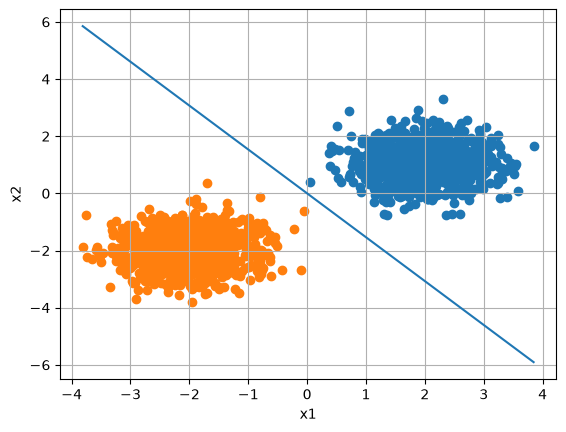

In [11]:
plt.scatter(x[y == 1, 0], x[y == 1, 1])
plt.scatter(x[y == -1, 0], x[y == -1, 1])

x1 = np.linspace(x[:, 0].min(), x[:, 0].max(), 100)
x2 = -(w[0] * x1 + b) / w[1]

plt.plot(x1, x2)

plt.xlabel("x1")
plt.ylabel("x2")
plt.grid()
plt.show()

## 8.python新知识

1.X_pos = np.random.normal(
    loc=[2, 2],
    scale=0.6,
    size=(n, 2)
)
loc是均值，scale是标准差，size(n, 2)生成n行2列的数据

2.X = np.vstack((a, b))，表示数据垂直叠加，两行两列叠加两行两列叠加后为四行两列。y = np.concatenate((y_pos, y_neg))横向叠加在一个数组中。

3.[]表示数组，np.zeros()才是数组，才能被用作矩阵

4.x.shape[0]表示行数，1表示列数。因为是二维。

5.对于矩阵来说，x[i]表示第i行，对于一维数组，@相乘不用转置

6.for i in range(...)，Python 每次循环都会自动给 i 下一个值。即使你写：i = 0下一次循环 Python 还是会按照 range() 继续执行。

7.对于需要判断后才能确定要不要继续循环的，需要在外层加入一个判读循环

8.np.where(条件, 条件成立时的值, 条件不成立时的值)

9.y_pred == y:判断语句得到的结果是0/1。

10.model.coef_ 表示 sklearn 训练好的模型中的权重系数，model.intercept_ 表示模型训练得到的截距/偏置项，intercept 本身就是“截距”的意思。

11.plt.legend() 的作用是显示图例。前提是你前面画图时设置了label。图例是一个独立的小方框，用于汇总label。

12.plt.plot:画线。plt.scatter(横坐标, 纵坐标)。x[条件, 列号]表示取出满足“条件”的那些行，再取指定的列。

13.np.linspace(最小值, 最大值, 100)：就是在最小值和最大值之间，均匀生成 100 个数。x[:, 0]表示取 x 的第 0 列，也就是所有样本的横坐标。